# DSA 4060 - Week 2 Practical Task
## Recommendation Data and Popularity Baselines

**Dataset:** `DSA_4060_Week2_Movie_Ratings.csv` - users' ratings of movies.

This notebook works through the seven tasks in the brief:

1. Load and inspect the dataset
2. Clean the dataset
3. Explore the interaction data
4. Build a user-item interaction matrix
5. Calculate sparsity
6. Build a popularity-based recommender
7. Interpret the results

Every step is preceded by a short explanation of *what* is being done and *why* it
matters for a recommender system.

### Setup

We use `pandas` for the data work and `matplotlib` for two small charts. `numpy` is
used for the sparsity arithmetic. Nothing outside the standard scientific stack is
required, so the notebook runs anywhere.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings: show enough columns/rows to read the tables comfortably.
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

# Chart styling used throughout: one recessive grid, one accent colour,
# dark ink for text. Single-series charts need no legend.
ACCENT = "#2a78d6"
INK = "#0b0b0b"
MUTED = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.edgecolor": "#d8d7d3",
    "axes.labelcolor": MUTED,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

DATA_PATH = "DSA_4060_Week2_Movie_Ratings.csv"
print("Libraries loaded. pandas", pd.__version__)

Libraries loaded. pandas 2.3.3


---

## Task 1 - Load and inspect the dataset

Before cleaning anything we look at the raw file exactly as it was supplied. The goal
is to answer three questions: what columns exist and what type is each, how big is the
dataset, and what is visibly wrong with it (missing values, repeated rows).

We deliberately inspect **before** cleaning so that the cleaning step can be justified
by evidence rather than assumption.

In [2]:
ratings_raw = pd.read_csv(DATA_PATH)

print("First 10 records:")
ratings_raw.head(10)

First 10 records:


,user_id,movie_id,movie_title,rating,timestamp
0,U001,M001,Nairobi Nights,3,2026-01-01T08:00:00Z
1,U004,M001,Nairobi Nights,4,2026-01-06T09:00:00Z
2,U007,M001,Nairobi Nights,2,2026-01-11T10:00:00Z
3,U010,M001,Nairobi Nights,2,2026-01-16T11:00:00Z
4,U013,M001,Nairobi Nights,4,2026-01-21T12:00:00Z
5,U016,M001,Nairobi Nights,3,2026-01-26T13:00:00Z
6,U019,M001,Nairobi Nights,3,2026-01-31T14:00:00Z
7,U022,M001,Nairobi Nights,2,2026-02-05T15:00:00Z
8,U025,M001,Nairobi Nights,2,2026-02-10T16:00:00Z
9,U028,M001,Nairobi Nights,4,2026-02-15T17:00:00Z


The file carries one extra column beyond the brief's description: `movie_title`. It is
a human-readable label for `movie_id`, which is convenient when we present the
recommendations - a list of titles is far more useful to a reader than a list of IDs.

In [3]:
print("Dataset dimensions (rows, columns):", ratings_raw.shape)
print()
print("Data types:")
print(ratings_raw.dtypes)

Dataset dimensions (rows, columns): (509, 5)

Data types:
user_id        object
movie_id       object
movie_title    object
rating          int64
timestamp      object
dtype: object


In [4]:
# A compact structural summary: non-null counts and memory use.
ratings_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 509 entries, 0 to 508
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      507 non-null    object
 1   movie_id     508 non-null    object
 2   movie_title  508 non-null    object
 3   rating       509 non-null    int64 
 4   timestamp    509 non-null    object
dtypes: int64(1), object(4)
memory usage: 20.0+ KB


### Missing values and duplicates

Two distinct problems are checked separately:

- **Missing values** - a rating with no `user_id` or no `movie_id` cannot be placed in
  the user-item matrix, because we do not know which cell it belongs to.
- **Duplicate records** - identical rows repeated in the file. These inflate the
  rating counts and would bias a popularity ranking, which is driven by counts.

In [5]:
print("Missing values per column:")
print(ratings_raw.isna().sum())
print()
print("Exact duplicate rows:", ratings_raw.duplicated().sum())
print()
print("The duplicated rows:")
ratings_raw[ratings_raw.duplicated(keep=False)].sort_values(list(ratings_raw.columns))

Missing values per column:
user_id        2
movie_id       1
movie_title    1
rating         0
timestamp      0
dtype: int64

Exact duplicate rows: 3

The duplicated rows:


,user_id,movie_id,movie_title,rating,timestamp
88,U012,M008,The Long Journey,3,2026-03-25T12:00:00Z
501,U012,M008,The Long Journey,3,2026-03-25T12:00:00Z
17,U023,M002,Savannah Run,4,2026-02-04T13:00:00Z
500,U023,M002,Savannah Run,4,2026-02-04T13:00:00Z
205,U023,M018,The Silent Drum,3,2026-06-08T09:00:00Z
502,U023,M018,The Silent Drum,3,2026-06-08T09:00:00Z


In [6]:
# Are the ratings inside the expected scale? Inspect every distinct value.
print("Distinct rating values and how often each occurs:")
print(ratings_raw["rating"].value_counts().sort_index())
print()
print("Rows whose rating falls outside the 1-5 scale:")
ratings_raw[~ratings_raw["rating"].between(1, 5)]

Distinct rating values and how often each occurs:
rating
-1      1
 0      1
 1      2
 2     90
 3    163
 4    184
 5     67
 6      1
Name: count, dtype: int64

Rows whose rating falls outside the 1-5 scale:


,user_id,movie_id,movie_title,rating,timestamp
506,U006,M010,Beyond the Horizon,0,2026-08-18T09:00:00Z
507,U028,M015,The Green Valley,6,2026-08-19T13:00:00Z
508,U041,M023,The Startup,-1,2026-08-20T14:00:00Z


**What the inspection found**

| Problem | Count |
|---|---|
| Rows in the raw file | 509 |
| Exact duplicate rows | 3 |
| Rows with a missing `user_id` or `movie_id` | 3 |
| Ratings outside the 1-5 scale (`0`, `6`, `-1`) | 3 |

The rating column is stored as an integer, and its distinct values run from `-1` to
`6`. A 1-5 star scale is the obvious intent - `2`, `3`, `4` and `5` account for
almost every row - so `-1`, `0` and `6` are recording errors rather than a wider
scale.

---

## Task 2 - Clean the dataset

Three cleaning rules, applied in order, each matching one problem found above:

1. **Drop exact duplicate rows.** The same person rating the same film at the same
   second is a recording artefact, not two opinions.
2. **Drop rows with a missing `user_id` or `movie_id`.** These cannot be assigned to a
   cell of the user-item matrix. We do not impute them - inventing a user or a film
   would fabricate an interaction that never happened.
3. **Drop ratings outside the 1-5 scale.** `-1`, `0` and `6` are impossible on this
   scale, so the value is untrustworthy even though the user and movie are known.

We keep the row count at each step so the effect of each rule is visible and auditable.

In [7]:
ratings = ratings_raw.copy()
n_start = len(ratings)

# 1. Remove exact duplicate records.
ratings = ratings.drop_duplicates()
n_after_dupes = len(ratings)

# 2. Remove records with a missing user or movie ID.
ratings = ratings.dropna(subset=["user_id", "movie_id"])
n_after_missing = len(ratings)

# 3. Keep only ratings on the expected 1-5 scale.
RATING_MIN, RATING_MAX = 1, 5
ratings = ratings[ratings["rating"].between(RATING_MIN, RATING_MAX)]
n_after_scale = len(ratings)

ratings = ratings.reset_index(drop=True)

cleaning_log = pd.DataFrame({
    "step": [
        "0. Raw file",
        "1. Removed exact duplicates",
        "2. Removed missing user/movie IDs",
        "3. Removed ratings outside 1-5",
    ],
    "rows_remaining": [n_start, n_after_dupes, n_after_missing, n_after_scale],
    "rows_removed": [
        0,
        n_start - n_after_dupes,
        n_after_dupes - n_after_missing,
        n_after_missing - n_after_scale,
    ],
})
cleaning_log

,step,rows_remaining,rows_removed
0,0. Raw file,509,0
1,1. Removed exact duplicates,506,3
2,2. Removed missing user/movie IDs,503,3
3,3. Removed ratings outside 1-5,500,3


In [8]:
# Confirm the cleaning worked: no duplicates, no missing IDs, ratings within scale.
print("Exact duplicates remaining:", ratings.duplicated().sum())
print("Missing user_id remaining: ", ratings["user_id"].isna().sum())
print("Missing movie_id remaining:", ratings["movie_id"].isna().sum())
print()
print("Rating scale check -> min:", ratings["rating"].min(), "| max:", ratings["rating"].max())
print("All ratings within 1-5:", bool(ratings["rating"].between(RATING_MIN, RATING_MAX).all()))
print()
print("Clean dataset dimensions:", ratings.shape)

Exact duplicates remaining: 0
Missing user_id remaining:  0
Missing movie_id remaining: 0

Rating scale check -> min: 1 | max: 5
All ratings within 1-5: True

Clean dataset dimensions: (500, 5)


### One thing that is *not* a duplicate

Some users appear more than once against the same film, with a different timestamp and
sometimes a different score - for example `U002` rated *Coastal Dreams* on three
separate dates. These are **not** duplicate records: they are repeat ratings, a user
changing their mind over time, and the brief only asks us to remove duplicates.

They still matter, because a user-item matrix has exactly one cell per user-film pair.
We check how many there are here, and resolve them in Task 4 by averaging each user's
ratings for a film.

In [9]:
repeat_pairs = ratings.duplicated(subset=["user_id", "movie_id"]).sum()
distinct_pairs = ratings.groupby(["user_id", "movie_id"]).ngroups

print("Ratings after cleaning:                ", len(ratings))
print("Distinct (user, movie) pairs:          ", distinct_pairs)
print("Extra ratings from repeat viewings:    ", repeat_pairs)
print()
print("Example of a repeat rating:")
ratings[(ratings["user_id"] == "U002") & (ratings["movie_id"] == "M004")]

Ratings after cleaning:                 500
Distinct (user, movie) pairs:           430
Extra ratings from repeat viewings:     70

Example of a repeat rating:


,user_id,movie_id,movie_title,rating,timestamp
46,U002,M004,Coastal Dreams,3,2026-03-19T08:00:00Z
321,U002,M004,Coastal Dreams,5,2026-07-13T08:00:00Z
355,U002,M004,Coastal Dreams,3,2026-03-11T09:00:00Z
402,U002,M004,Coastal Dreams,3,2026-06-07T12:00:00Z


---

## Task 3 - Explore the interaction data

These six numbers describe the *shape of the interaction data*, which is what decides
whether a recommender can work at all. A recommender learns from interactions, so the
count of users, the count of items and how those interactions spread across them are
the limiting factors on anything we build afterwards.

In [10]:
total_ratings = len(ratings)
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
average_rating = ratings["rating"].mean()

ratings_per_user = ratings["user_id"].value_counts()
ratings_per_movie = ratings["movie_id"].value_counts()

most_active_user = ratings_per_user.index[0]
most_active_user_count = int(ratings_per_user.iloc[0])

most_rated_movie_id = ratings_per_movie.index[0]
most_rated_movie_count = int(ratings_per_movie.iloc[0])
title_lookup = ratings.drop_duplicates("movie_id").set_index("movie_id")["movie_title"]
most_rated_movie_title = title_lookup[most_rated_movie_id]

summary = pd.DataFrame({
    "measure": [
        "Total number of ratings",
        "Number of unique users",
        "Number of unique movies",
        "Most active user",
        "Most-rated movie",
        "Average rating in the dataset",
    ],
    "value": [
        f"{total_ratings}",
        f"{n_users}",
        f"{n_movies}",
        f"{most_active_user} ({most_active_user_count} ratings)",
        f"{most_rated_movie_title} [{most_rated_movie_id}] ({most_rated_movie_count} ratings)",
        f"{average_rating:.2f}",
    ],
})
summary

,measure,value
0,Total number of ratings,500
1,Number of unique users,50
2,Number of unique movies,24
3,Most active user,U010 (17 ratings)
4,Most-rated movie,Nairobi Nights [M001] (37 ratings)
5,Average rating in the dataset,3.45


In [11]:
# The most-rated film is a tie, so report every film on the top count.
top_count = ratings_per_movie.max()
tied = ratings_per_movie[ratings_per_movie == top_count]
print(f"Films tied on the highest rating count ({top_count} ratings each):")
for mid, cnt in tied.items():
    print(f"  {mid}  {title_lookup[mid]}")

Films tied on the highest rating count (37 ratings each):
  M001  Nairobi Nights
  M005  Mountain Echoes


In [12]:
print("Ten most active users (ratings submitted):")
print(ratings_per_user.head(10).to_string())
print()
print("Ten most-rated movies (ratings received):")
top_rated_counts = ratings_per_movie.head(10).rename("num_ratings").to_frame()
top_rated_counts.insert(0, "movie_title", [title_lookup[m] for m in top_rated_counts.index])
top_rated_counts

Ten most active users (ratings submitted):
user_id
U010    17
U035    14
U032    14
U016    13
U011    12
U007    12
U037    12
U006    12
U030    12
U045    12

Ten most-rated movies (ratings received):


,movie_title,num_ratings
movie_id,,
M001,Nairobi Nights,37
M005,Mountain Echoes,37
M002,Savannah Run,34
M003,The Last Matatu,34
M006,City of Tomorrow,34
M004,Coastal Dreams,27
M022,Wings of Hope,21
M008,The Long Journey,20
M018,The Silent Drum,19


### How the ratings are distributed

The average alone can hide a skew, so we plot the full distribution. A rating scale
that leans high is normal in real recommendation data - people mostly choose to watch
films they expect to like - and it matters for our recommender, because it means the
*average rating* column will be squeezed into a narrow band near the top of the scale.

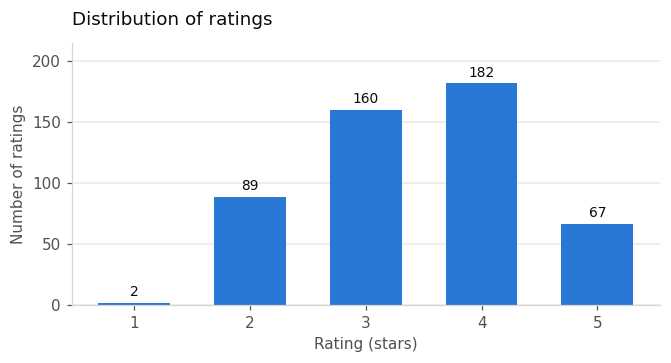

Mean rating: 3.45   |   Median rating: 3.0


In [13]:
dist = ratings["rating"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6.2, 3.4))
bars = ax.bar(dist.index.astype(str), dist.values, color=ACCENT, width=0.62)

# Direct value labels: with five bars, labelling each is clearer than a y-axis read-off.
for bar, value in zip(bars, dist.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 3, f"{value}",
            ha="center", va="bottom", fontsize=9, color=INK)

ax.set_title("Distribution of ratings", color=INK, fontsize=12, pad=12, loc="left")
ax.set_xlabel("Rating (stars)")
ax.set_ylabel("Number of ratings")
ax.set_ylim(0, dist.max() * 1.18)
ax.yaxis.grid(True, color="#ebeae6", linewidth=1)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print(f"Mean rating: {average_rating:.2f}   |   Median rating: {ratings['rating'].median():.1f}")

The distribution is centred on 3 and 4 stars and there are very few 1s. The mean of
**3.45** sits above the scale midpoint of 3, confirming the mild positive skew
described above.

---

## Task 4 - Create a user-item interaction matrix

The user-item matrix is the standard representation behind almost every recommender:
one row per user, one column per item, and the rating in the cell where they meet. An
empty cell means *this user has not rated this film* - it is unknown, not zero. That
distinction is important: treating an unrated film as a rating of 0 would tell the
model the user disliked it, which we have no evidence for.

We build it with `pivot_table` rather than `pivot` because of the repeat ratings found
in Task 2. `aggfunc="mean"` collapses a user's several ratings for one film into that
user's average opinion of it, which is the single number the cell is meant to hold.

In [14]:
user_item_matrix = ratings.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating",
    aggfunc="mean",     # collapse repeat ratings into one value per user-film pair
)

print("User-item matrix dimensions (users x movies):", user_item_matrix.shape)
print("Filled cells (observed user-film pairs):", int(user_item_matrix.notna().sum().sum()))
print()
print("A small section of the matrix - first 8 users, first 8 movies:")
user_item_matrix.iloc[:8, :8]

User-item matrix dimensions (users x movies): (50, 24)
Filled cells (observed user-film pairs): 430

A small section of the matrix - first 8 users, first 8 movies:


movie_id,M001,M002,M003,M004,M005,M006,M007,M008
user_id,,,,,,,,
U001,3.000000,2.0,NaN,NaN,4.0,4.0,NaN,NaN
U002,3.000000,NaN,NaN,3.5,NaN,NaN,3.0,NaN
U003,NaN,NaN,NaN,NaN,4.0,NaN,NaN,4.0
U004,4.000000,NaN,NaN,NaN,3.0,3.0,NaN,NaN
U005,2.000000,4.0,NaN,3.0,NaN,NaN,5.0,NaN
U006,3.000000,3.0,NaN,5.0,4.0,NaN,NaN,3.0
U007,2.333333,NaN,NaN,NaN,5.0,4.0,NaN,NaN
U008,3.000000,2.0,NaN,NaN,3.0,4.0,5.0,NaN


`NaN` marks a film the user has not rated. Even in this small 8x8 window most cells are
empty, which is the pattern the next task quantifies.

In [15]:
# The same window with titles instead of IDs, to show what the matrix actually says.
window = user_item_matrix.iloc[:8, :8].copy()
window.columns = [f"{m}\n{title_lookup[m]}" for m in window.columns]
window.round(1)

,M001\nNairobi Nights,M002\nSavannah Run,M003\nThe Last Matatu,M004\nCoastal Dreams,M005\nMountain Echoes,M006\nCity of Tomorrow,M007\nHidden Lake,M008\nThe Long Journey
user_id,,,,,,,,
U001,3.0,2.0,NaN,NaN,4.0,4.0,NaN,NaN
U002,3.0,NaN,NaN,3.5,NaN,NaN,3.0,NaN
U003,NaN,NaN,NaN,NaN,4.0,NaN,NaN,4.0
U004,4.0,NaN,NaN,NaN,3.0,3.0,NaN,NaN
U005,2.0,4.0,NaN,3.0,NaN,NaN,5.0,NaN
U006,3.0,3.0,NaN,5.0,4.0,NaN,NaN,3.0
U007,2.3,NaN,NaN,NaN,5.0,4.0,NaN,NaN
U008,3.0,2.0,NaN,NaN,3.0,4.0,5.0,NaN


---

## Task 5 - Calculate sparsity

Sparsity is the share of the matrix that is empty:

$$\text{Sparsity} = 1 - \frac{\text{Observed ratings}}{\text{Number of users} \times \text{Number of movies}}$$

The numerator is the number of **filled cells** - distinct user-film pairs - because
that is what occupies space in the matrix. The 500 cleaned ratings include repeat
viewings that share a cell, so the two figures differ slightly and we report both.

In [16]:
n_users_matrix, n_movies_matrix = user_item_matrix.shape
possible_cells = n_users_matrix * n_movies_matrix
observed_cells = int(user_item_matrix.notna().sum().sum())

sparsity = 1 - (observed_cells / possible_cells)
density = 1 - sparsity

print(f"Users                       : {n_users_matrix}")
print(f"Movies                      : {n_movies_matrix}")
print(f"Possible cells (users x movies): {possible_cells}")
print(f"Observed ratings (filled cells): {observed_cells}")
print()
print(f"Sparsity = 1 - {observed_cells}/{possible_cells} = {sparsity:.4f}  ->  {sparsity * 100:.2f}% empty")
print(f"Density  =                              {density:.4f}  ->  {density * 100:.2f}% filled")
print()
print(f"(Using all {total_ratings} cleaned ratings instead of distinct pairs: "
      f"{1 - total_ratings / possible_cells:.4f} -> {(1 - total_ratings / possible_cells) * 100:.2f}%)")

Users                       : 50
Movies                      : 24
Possible cells (users x movies): 1200
Observed ratings (filled cells): 430

Sparsity = 1 - 430/1200 = 0.6417  ->  64.17% empty
Density  =                              0.3583  ->  35.83% filled

(Using all 500 cleaned ratings instead of distinct pairs: 0.5833 -> 58.33%)


### What the sparsity result means

The matrix is **64.17% empty**: of the 1,200 possible user-film combinations, only 430
have actually been rated, so roughly one cell in three is filled.

In plain terms, **the average user has rated about 9 of the 24 films** and has no
recorded opinion on the other 15. Recommending is exactly the job of guessing what
belongs in those empty cells.

Two consequences follow:

- **This dataset is unusually dense for a recommender.** Real systems sit at 95-99.9%
  sparsity - the MovieLens 100K benchmark is about 93.7% empty - because their
  catalogues run to thousands of items that any one person will never touch. Our 24
  films are few enough that most users have seen a good fraction of them.
- **Sparsity is what makes recommendation hard, and it grows with the catalogue.** The
  denominator grows with every new film added, while a user's viewing habits do not,
  so the matrix empties out as the service grows. Methods that rely on overlap between
  users - collaborative filtering - lose traction when two users share almost no rated
  films. A popularity baseline like the one below sidesteps the problem entirely by
  ignoring the individual user, which is both its strength and its weakness.

---

## Task 6 - Build a popularity-based recommender

A popularity recommender ranks items by how well they are received overall and shows
the same list to everyone. It needs two numbers per film:

- **Average rating** - how much the people who watched it liked it.
- **Number of ratings** - how much evidence we have for that average.

Both are needed, and the second is the guard on the first. A film rated 5.0 by one
person has a perfect average built on a single opinion; a film rated 4.3 by thirty
people is the safer recommendation. The brief's **minimum of 10 ratings** is exactly
this guard: it filters out films whose averages are too thin to trust before ranking
on the average.

In [17]:
MIN_RATINGS = 10

movie_stats = (
    ratings.groupby(["movie_id", "movie_title"])["rating"]
    .agg(avg_rating="mean", num_ratings="count")
    .reset_index()
    .sort_values("avg_rating", ascending=False)
)
movie_stats["avg_rating"] = movie_stats["avg_rating"].round(2)

print(f"Statistics for all {len(movie_stats)} movies (sorted by average rating):")
movie_stats.reset_index(drop=True)

Statistics for all 24 movies (sorted by average rating):


,movie_id,movie_title,avg_rating,num_ratings
0,M021,Market Day,4.47,15
1,M013,Midnight in Mombasa,4.35,17
2,M014,Code Breakers,4.25,16
3,M020,Home Again,4.13,15
4,M019,Future Africa,4.13,15
5,M007,Hidden Lake,4.12,16
6,M006,City of Tomorrow,3.91,34
7,M005,Mountain Echoes,3.86,37
8,M012,The Final Goal,3.76,17
9,M004,Coastal Dreams,3.67,27


In [18]:
eligible = movie_stats[movie_stats["num_ratings"] >= MIN_RATINGS]

print(f"Movies in the dataset          : {len(movie_stats)}")
print(f"Movies with >= {MIN_RATINGS} ratings      : {len(eligible)}")
print(f"Movies excluded as too thin    : {len(movie_stats) - len(eligible)}")
print()
print(f"Ratings received per movie -> min: {movie_stats['num_ratings'].min()}, "
      f"max: {movie_stats['num_ratings'].max()}")

Movies in the dataset          : 24
Movies with >= 10 ratings      : 24
Movies excluded as too thin    : 0

Ratings received per movie -> min: 13, max: 37


In [19]:
# Rank by average rating; break ties on the number of ratings, so that where two
# films are equally liked the better-evidenced one is recommended first.
top_10 = (
    eligible.sort_values(["avg_rating", "num_ratings"], ascending=[False, False])
    .head(10)
    .reset_index(drop=True)
)
top_10.insert(0, "rank", range(1, len(top_10) + 1))

print("Top 10 recommended movies (>= 10 ratings, ranked by average rating):")
top_10

Top 10 recommended movies (>= 10 ratings, ranked by average rating):


,rank,movie_id,movie_title,avg_rating,num_ratings
0,1,M021,Market Day,4.47,15
1,2,M013,Midnight in Mombasa,4.35,17
2,3,M014,Code Breakers,4.25,16
3,4,M020,Home Again,4.13,15
4,5,M019,Future Africa,4.13,15
5,6,M007,Hidden Lake,4.12,16
6,7,M006,City of Tomorrow,3.91,34
7,8,M005,Mountain Echoes,3.86,37
8,9,M012,The Final Goal,3.76,17
9,10,M004,Coastal Dreams,3.67,27


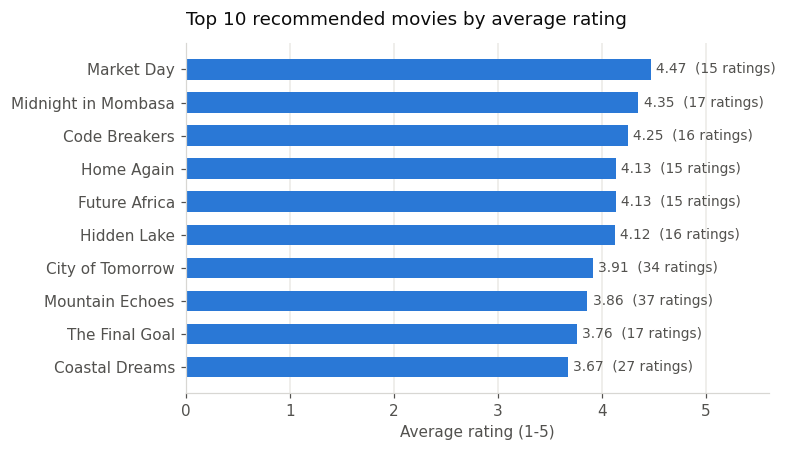

In [20]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
order = top_10.iloc[::-1]  # highest at the top of a horizontal bar chart

bars = ax.barh(order["movie_title"], order["avg_rating"], color=ACCENT, height=0.62)

for bar, avg, n in zip(bars, order["avg_rating"], order["num_ratings"]):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height() / 2,
            f"{avg:.2f}  ({n} ratings)", va="center", fontsize=9, color=MUTED)

ax.set_title("Top 10 recommended movies by average rating",
             color=INK, fontsize=12, pad=12, loc="left")
ax.set_xlabel("Average rating (1-5)")
ax.set_xlim(0, 5.6)
ax.xaxis.grid(True, color="#ebeae6", linewidth=1)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [21]:
# Save the recommendations for submission.
OUTPUT_PATH = "top_10_recommended_movies.csv"
top_10.to_csv(OUTPUT_PATH, index=False)

print(f"Saved {len(top_10)} recommendations to {OUTPUT_PATH}")
pd.read_csv(OUTPUT_PATH)

Saved 10 recommendations to top_10_recommended_movies.csv


,rank,movie_id,movie_title,avg_rating,num_ratings
0,1,M021,Market Day,4.47,15
1,2,M013,Midnight in Mombasa,4.35,17
2,3,M014,Code Breakers,4.25,16
3,4,M020,Home Again,4.13,15
4,5,M019,Future Africa,4.13,15
5,6,M007,Hidden Lake,4.12,16
6,7,M006,City of Tomorrow,3.91,34
7,8,M005,Mountain Echoes,3.86,37
8,9,M012,The Final Goal,3.76,17
9,10,M004,Coastal Dreams,3.67,27


---

## Task 7 - Interpret the results

### Why these movies appear at the top

The ranking is the two columns of Task 6 applied in order. First the **minimum of 10
ratings** removes films with too little evidence; here every one of the 24 films clears
that bar (the least-rated has 13), so the filter changes nothing for this particular
dataset - but it is the part of the rule that would matter most on a real catalogue,
where a long tail of films has one or two ratings each. Then the survivors are sorted
by **average rating**, so the films at the top are those whose viewers scored them
highest on average.

*Market Day* leads on an average of **4.47 from 15 ratings**, followed by *Midnight in
Mombasa* (**4.35 from 17**) and *Code Breakers* (**4.25 from 16**). Two things are worth
noticing about the list:

- **The spread is narrow.** First place and tenth place are separated by only about 0.8
  of a star, in a dataset where the overall mean is 3.45. The ranking is real but the
  gaps between neighbouring films are small, and a handful of extra ratings could
  reorder the middle of the list.
- **Popularity here means "well liked", not "most watched".** *Mountain Echoes* and
  *Nairobi Nights* received the most ratings (37 each), yet *Nairobi Nights* misses the
  top 10 entirely - plenty of people rated it, and they were lukewarm. Ranking by
  rating count instead of average would have produced a visibly different list.

### One advantage of popularity-based recommendation

**It works immediately for a brand-new user, and it costs almost nothing to run.** The
recommender needs no information whatsoever about the person being served - no history,
no profile, no similar users. That solves the *user cold-start* problem, the situation
where someone has just signed up and a personalised model has nothing to work from. It
is also a single `groupby` over the ratings table, cheap to compute and easy to explain
to a non-technical stakeholder, which is why it is the standard baseline that any
fancier model has to beat.

### Two limitations of this approach

**1. It is identical for every user - there is no personalisation.** Every user sees the
same ten films, so the recommender cannot tell a documentary enthusiast from a comedy
fan. The 64% of the matrix we measured as empty in Task 5 is precisely the individual
preference information this method throws away. Worse, some of these films will already
have been watched by the user - the recommender does not know or care - so part of the
list is wasted on each person.

**2. It creates a popularity feedback loop that buries the catalogue.** Films that are
already widely rated get recommended, which earns them more views and more ratings,
which keeps them at the top. Films with few ratings never surface, so they never
accumulate the ratings that would let them qualify - the `>= 10` threshold, necessary as
it is, locks them out. New releases suffer the same fate, which is the *item cold-start*
problem. The long tail of the catalogue becomes effectively invisible, and
recommendations grow steadily less diverse over time.

### Where this baseline leads next

The popularity model is the floor, not the ceiling. The natural next step is
**collaborative filtering**, which uses the user-item matrix built in Task 4 to find
users with similar rating patterns and recommend what those neighbours liked. It fixes
the personalisation gap directly - but, as Task 5 showed, it depends on users having
rated films in common, which is exactly what sparsity takes away as a catalogue grows.

---

## Summary of findings

| Measure | Value |
|---|---|
| Rows in the raw file | 509 |
| Rows removed in cleaning | 9 (3 duplicates, 3 missing IDs, 3 out-of-scale ratings) |
| Ratings after cleaning | 500 |
| Unique users | 50 |
| Unique movies | 24 |
| Distinct user-movie pairs | 430 |
| Most active user | U010 (17 ratings) |
| Most-rated movie | Mountain Echoes / Nairobi Nights (37 ratings each) |
| Average rating | 3.45 |
| Matrix size | 50 x 24 = 1,200 cells |
| Sparsity | 64.17% empty |
| Top recommendation | Market Day (4.47 from 15 ratings) |

**Files produced by this notebook**

- `top_10_recommended_movies.csv` - the ten recommended films with rank, average rating
  and rating count.